# 08 · Model comparison and selection
Primary selection metric: CV macro F1 (GroupKFold over the 80 train trips), student-test top-1 accuracy as a check.

In [1]:
import sys, os, glob, json
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pathsnap").is_dir()), None)
if _root is None:
    raise RuntimeError("src/pathsnap not found: unzip all zips of the set into the same pathsnap/ folder")
sys.path.insert(0, str(_root / "src")); os.chdir(_root / "notebooks")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from pathsnap import modeling
from pathsnap.evaluate import pick

FIG = "../outputs/figures"
res = pd.DataFrame([json.load(open(f)) for f in sorted(glob.glob("../outputs/models/M*.json")) if "tuned" not in f])
cols = ["model", "family", "config", "cv_macro_f1", "cv_macro_f1_std", "test_top1_acc", "test_route_continuity",
        "test_macro_f1", "test_log_loss", "test_precision", "test_recall", "train_macro_f1", "train_time_s", "infer_ms_per_point"]
table = res[cols].sort_values("cv_macro_f1", ascending=False)
table.to_csv("../outputs/model_comparison.csv", index=False)
table.round(4)

,model,family,config,cv_macro_f1,cv_macro_f1_std,test_top1_acc,test_route_continuity,test_macro_f1,test_log_loss,test_precision,test_recall,train_macro_f1,train_time_s,infer_ms_per_point
5,M6_lightgbm,Boosting,"lr=0.05, 400 trees, num_leaves=31",0.9356,0.0224,0.8875,0.7531,0.9351,0.0833,0.8875,0.8908,0.9548,4.4688,0.0676
4,M5_hist_gb,Boosting,"lr=0.1, max_iter=300, max_leaf_nodes=31",0.9345,0.0231,0.8840,0.7456,0.9330,0.0859,0.8840,0.8873,0.9466,2.2035,0.0141
3,M4_random_forest,Ensemble (bagging),"300 trees, max_depth=16, min_samples_leaf=5",0.9335,0.0222,0.8756,0.7453,0.9281,0.0884,0.8756,0.8788,0.9580,88.8392,0.0714
6,M7_mlp,Neural network,"64-32 ReLU, adam, lr=1e-3, early stopping",0.9297,0.0232,0.8765,0.7376,0.9287,0.0933,0.8765,0.8798,0.9432,18.6216,0.0044
0,M1_logreg,Linear,"C=1.0, L2, class_weight=balanced, scaled",0.9261,0.0241,0.8618,0.7164,0.9200,0.2198,0.8618,0.8651,0.9270,0.4618,0.0008
2,M3_knn,Instance-based,"k=25, distance-weighted, scaled",0.9237,0.0264,0.8587,0.7219,0.9182,0.1526,0.8587,0.8619,0.9986,0.0783,2.6335
1,M2_gaussian_nb,Probabilistic,var_smoothing=1e-9,0.9143,0.0193,0.8352,0.6848,0.9044,0.9440,0.8352,0.8383,0.9158,0.0885,0.0018


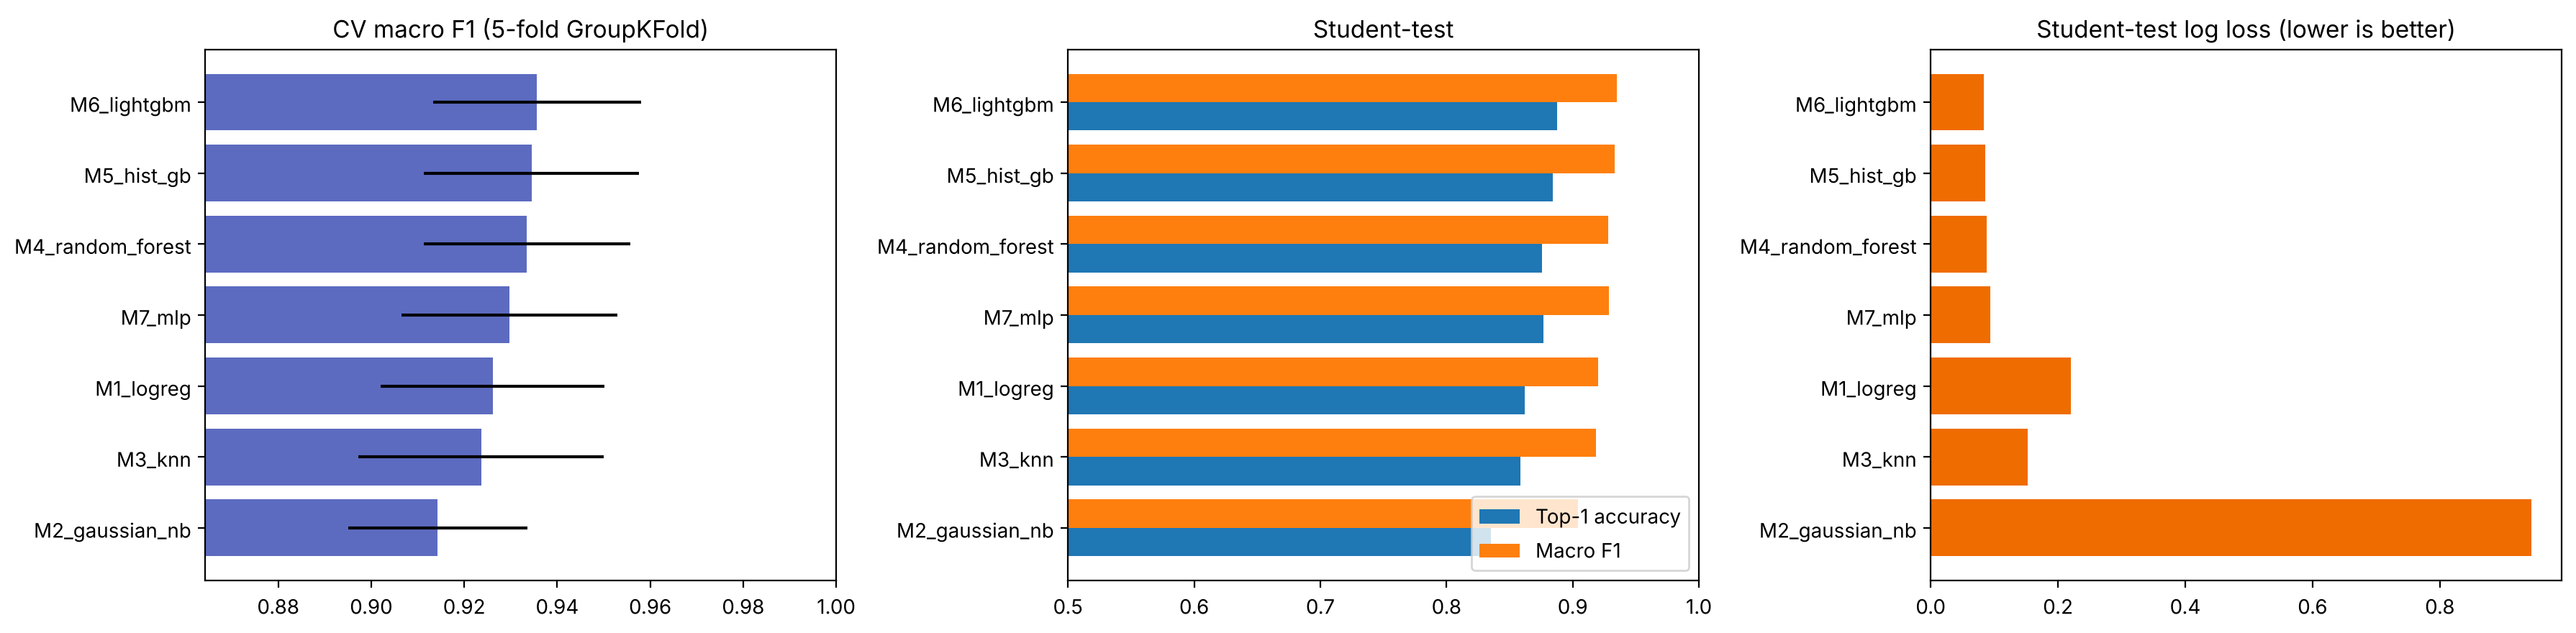

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
r = res.sort_values("cv_macro_f1")
ax[0].barh(r.model, r.cv_macro_f1, xerr=r.cv_macro_f1_std, color="#5c6bc0"); ax[0].set_title("CV macro F1 (5-fold GroupKFold)")
ax[0].set_xlim(r.cv_macro_f1.min() - .05, 1)
w = .4; y = np.arange(len(r))
ax[1].barh(y - w / 2, r.test_top1_acc, w, label="Top-1 accuracy"); ax[1].barh(y + w / 2, r.test_macro_f1, w, label="Macro F1")
ax[1].set_yticks(y, r.model); ax[1].set_xlim(.5, 1); ax[1].legend(loc="lower right"); ax[1].set_title("Student-test")
ax[2].barh(r.model, r.test_log_loss, color="#ef6c00"); ax[2].set_title("Student-test log loss (lower is better)")
plt.tight_layout(); plt.savefig(f"{FIG}/model_comparison.png", dpi=120)

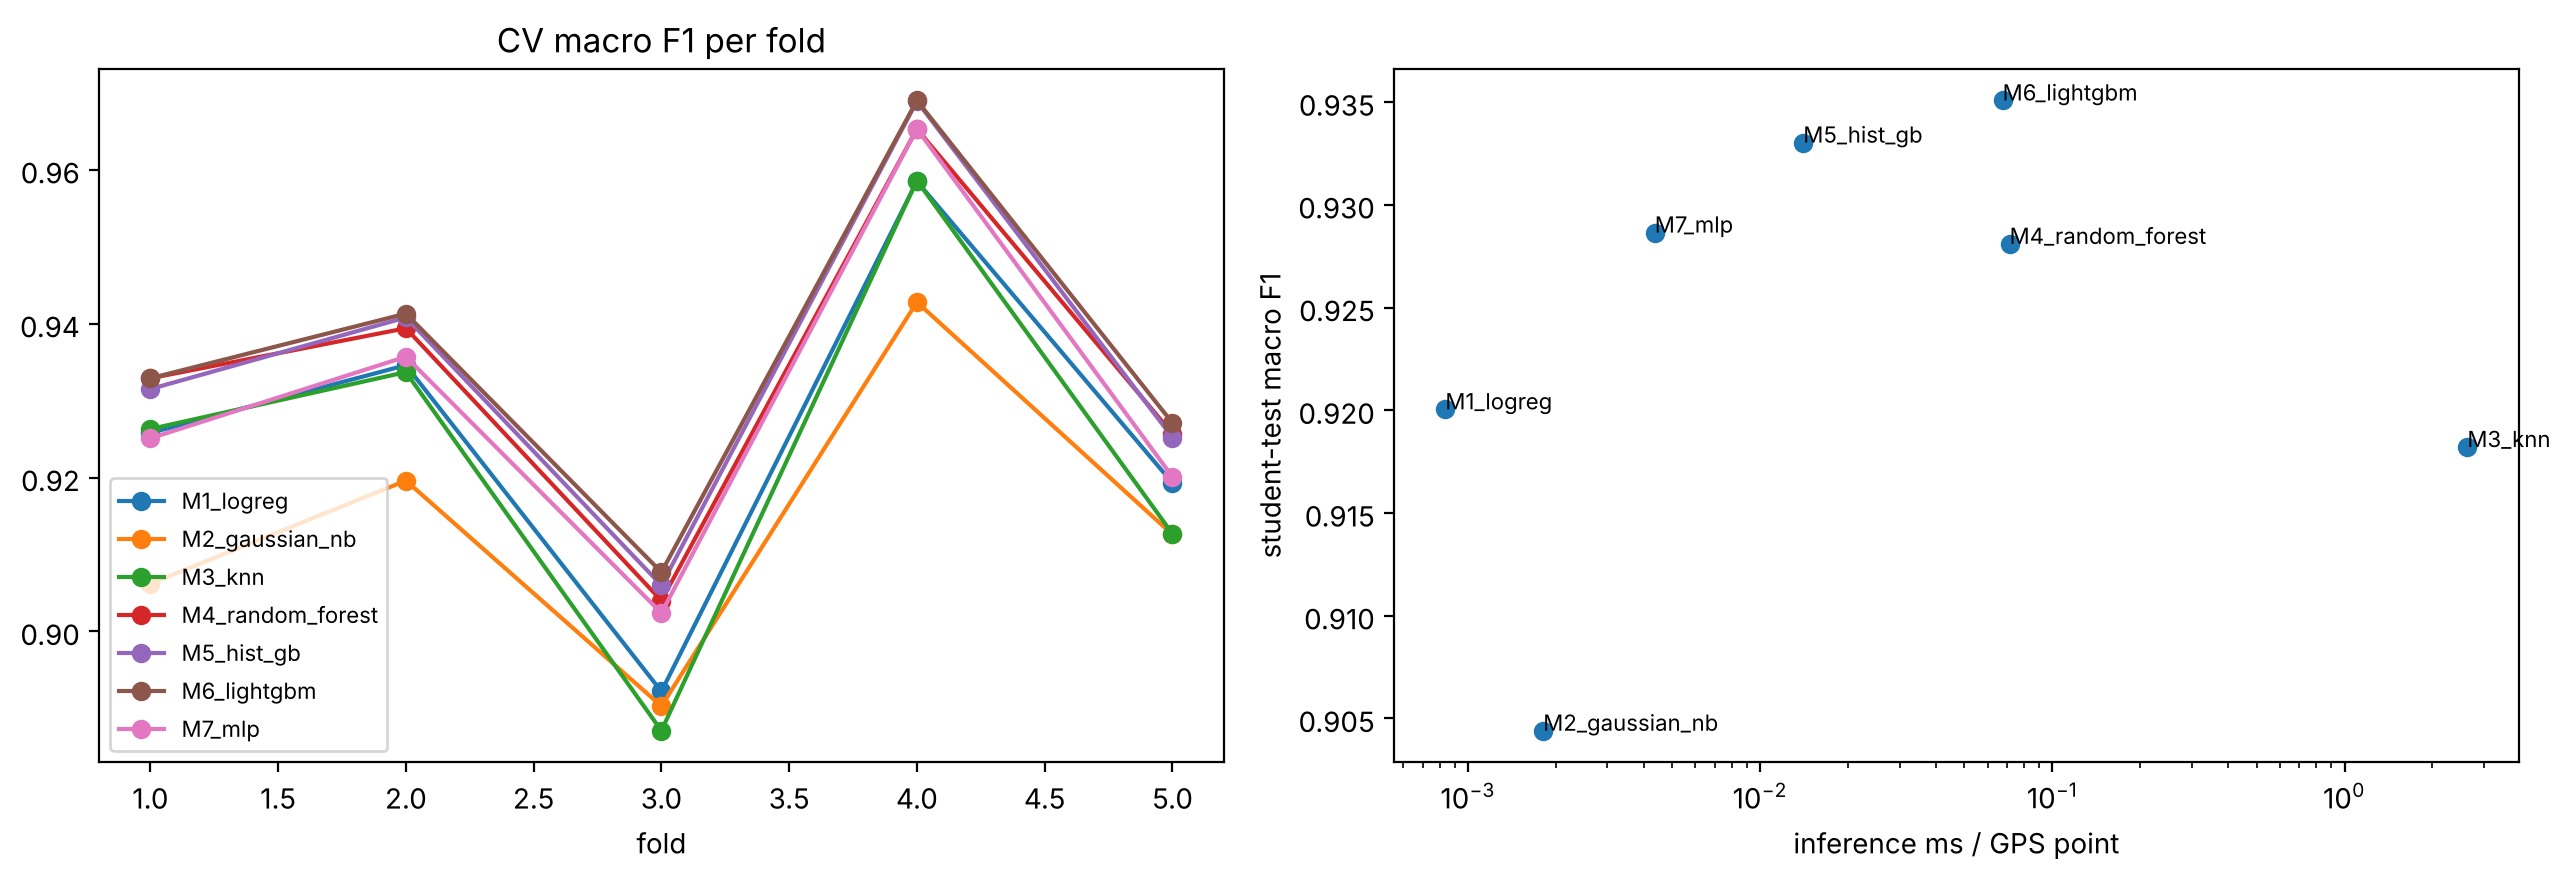

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for _, row in res.iterrows():
    ax[0].plot(range(1, 6), row.cv_folds, marker="o", label=row.model)
ax[0].set_xlabel("fold"); ax[0].set_title("CV macro F1 per fold"); ax[0].legend(fontsize=8)
ax[1].scatter(res.infer_ms_per_point, res.test_macro_f1)
for _, row in res.iterrows():
    ax[1].annotate(row.model, (row.infer_ms_per_point, row.test_macro_f1), fontsize=8)
ax[1].set_xscale("log"); ax[1].set_xlabel("inference ms / GPS point"); ax[1].set_ylabel("student-test macro F1")
plt.tight_layout(); plt.savefig(f"{FIG}/model_stability_speed.png", dpi=120)

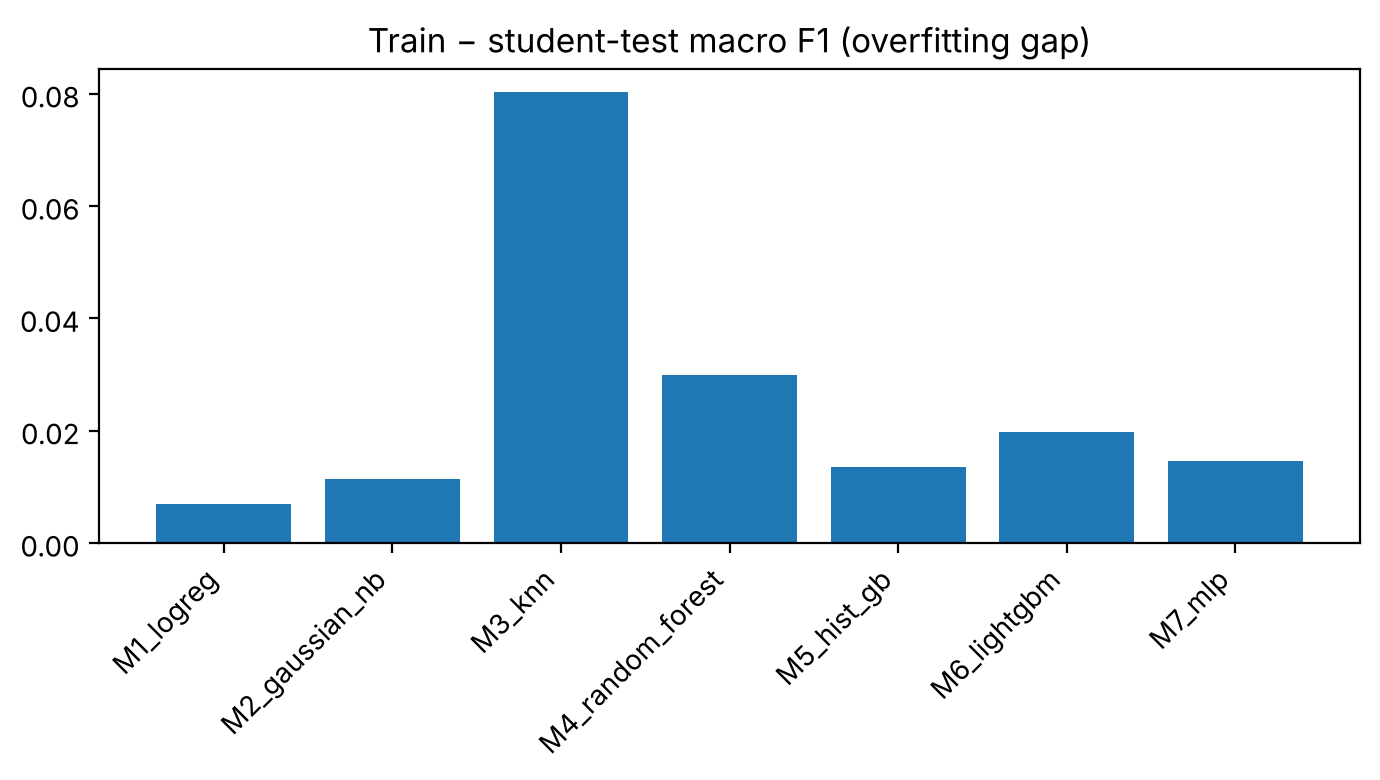

In [4]:
plt.figure(figsize=(7, 4))
plt.bar(res.model, res.train_macro_f1 - res.test_macro_f1); plt.xticks(rotation=45, ha="right")
plt.title("Train − student-test macro F1 (overfitting gap)"); plt.tight_layout()
plt.savefig(f"{FIG}/overfit_gap.png", dpi=120)

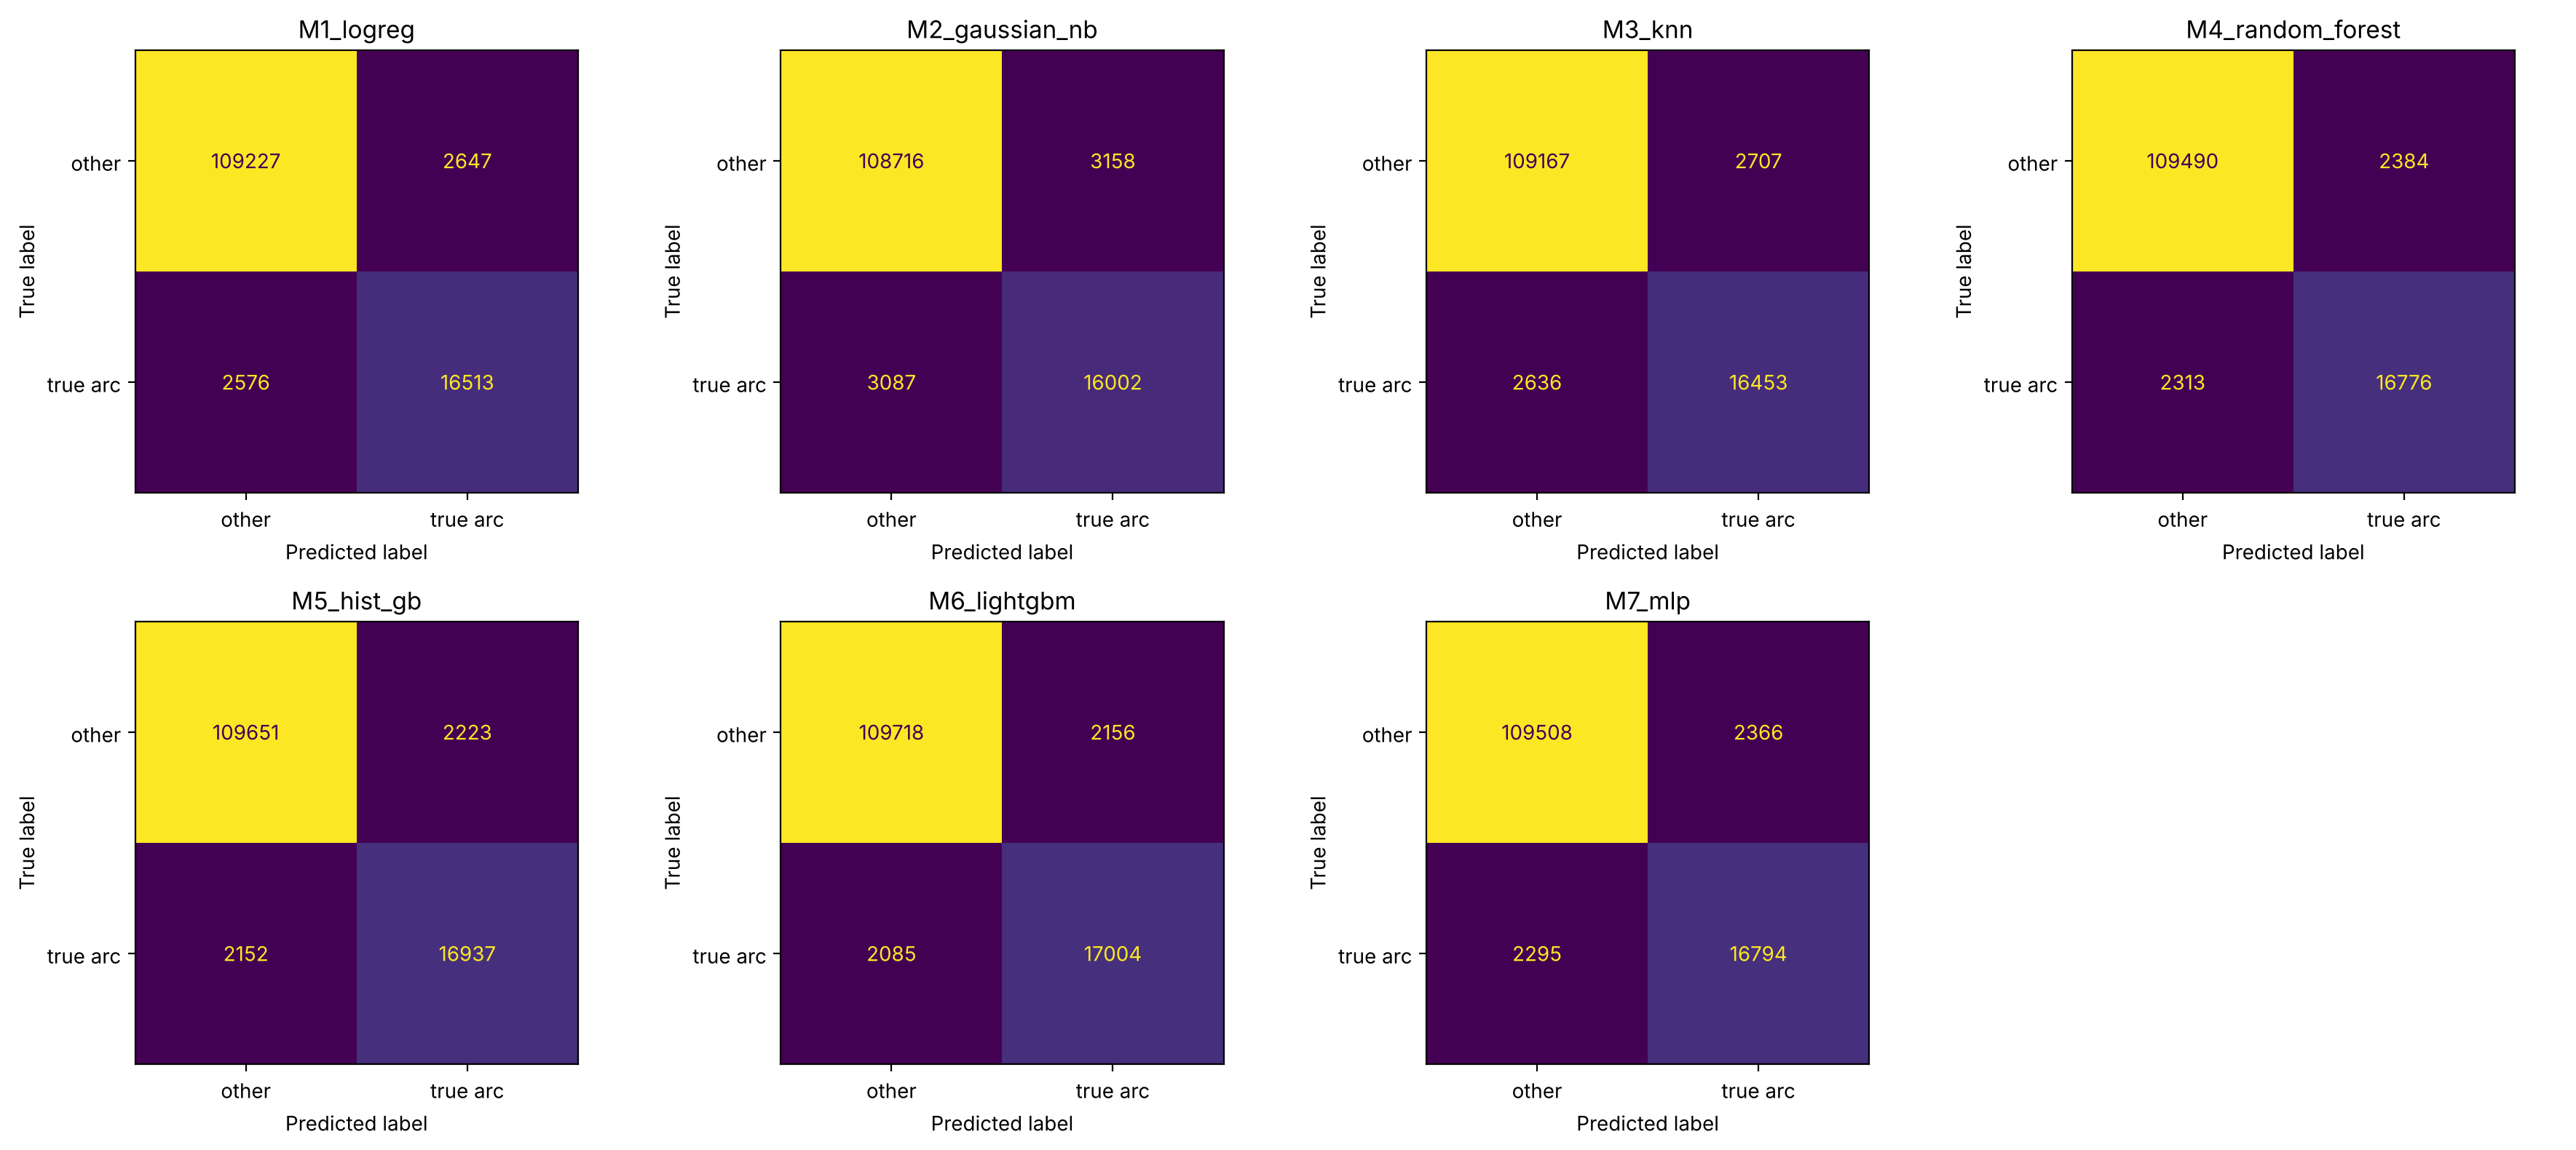

In [5]:
_, te = modeling.load_tables()
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, name in zip(axes.ravel(), res.model):
    m = joblib.load(f"../artifacts/models/{name}.joblib")
    sel = pick(te, modeling.proba(m, te[modeling.FEATURES].values))
    ConfusionMatrixDisplay(confusion_matrix(te.y, sel), display_labels=["other", "true arc"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.savefig(f"{FIG}/confusion_matrices.png", dpi=110)

In [6]:
best = table.iloc[0]
print("selected:", best.model, "| CV macro F1", round(best.cv_macro_f1, 4), "| test top-1", round(best.test_top1_acc, 4))

selected: M6_lightgbm | CV macro F1 0.9356 | test top-1 0.8875
